In [1]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import PIL
import cv2

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("OpenCV:", cv2.__version__)

print("\n✅ Environment is ready!")

Python: 3.13.16 (tags/v3.13.16:cbc944f, Sep 30 2026, 19:17:50) [MSC v.1944 64 bit (AMD64)]
TensorFlow: 2.21.0
NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1
OpenCV: 5.0.0

✅ Environment is ready!


In [2]:
from pathlib import Path

# Path to our dataset
dataset_path = Path("../dataset/chest_xray")

# Check that the dataset exists
print("Dataset path:", dataset_path.resolve())
print("Dataset exists:", dataset_path.exists())

# Show the folders inside the dataset
print("\nDataset contents:")
for item in dataset_path.iterdir():
    print("-", item.name)

Dataset path: D:\Tanu H\TanushrisSPace\Projects\DL MINI PROJECT\dataset\chest_xray
Dataset exists: True

Dataset contents:
- .DS_Store
- test
- train
- val


In [3]:
# Count images in each dataset split and class

splits = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]

dataset_counts = {}

for split in splits:
    dataset_counts[split] = {}

    for class_name in classes:
        folder = dataset_path / split / class_name

        # Count image files
        image_files = [
            f for f in folder.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        dataset_counts[split][class_name] = len(image_files)

# Display the results
print("IMAGE COUNTS")
print("=" * 40)

for split in splits:
    print(f"\n{split.upper()}")
    for class_name in classes:
        print(f"{class_name}: {dataset_counts[split][class_name]}")

# Total images
total_images = sum(
    dataset_counts[split][class_name]
    for split in splits
    for class_name in classes
)

print("\n" + "=" * 40)
print("TOTAL IMAGES:", total_images)

IMAGE COUNTS

TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VAL
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390

TOTAL IMAGES: 5856


In [4]:
# Create a DataFrame for easy analysis

count_data = []

for split in splits:
    for class_name in classes:
        count_data.append({
            "Dataset": split.upper(),
            "Class": class_name,
            "Images": dataset_counts[split][class_name]
        })

counts_df = pd.DataFrame(count_data)

print(counts_df)

  Dataset      Class  Images
0   TRAIN     NORMAL    1341
1   TRAIN  PNEUMONIA    3875
2     VAL     NORMAL       8
3     VAL  PNEUMONIA       8
4    TEST     NORMAL     234
5    TEST  PNEUMONIA     390


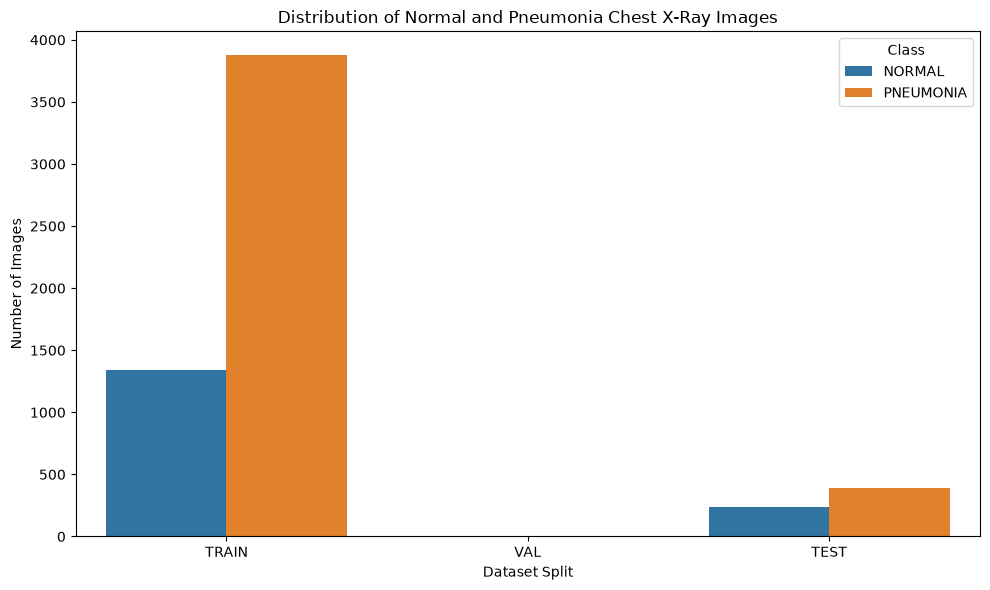

In [5]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=counts_df,
    x="Dataset",
    y="Images",
    hue="Class"
)

plt.title("Distribution of Normal and Pneumonia Chest X-Ray Images")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.legend(title="Class")
plt.tight_layout()

plt.show()

In [6]:
from PIL import Image

# Collect image information from all splits
image_info = []

for split in splits:
    for class_name in classes:
        folder = dataset_path / split / class_name

        for file in folder.iterdir():
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                try:
                    with Image.open(file) as img:
                        image_info.append({
                            "split": split,
                            "class": class_name,
                            "filename": file.name,
                            "width": img.width,
                            "height": img.height,
                            "mode": img.mode,
                            "format": img.format
                        })
                except Exception as e:
                    print("Error reading:", file, e)

image_info_df = pd.DataFrame(image_info)

print("Total images checked:", len(image_info_df))
print("\nImage formats:")
print(image_info_df["format"].value_counts())

print("\nColor modes:")
print(image_info_df["mode"].value_counts())

print("\nImage dimensions:")
print(image_info_df[["width", "height"]].describe())

Total images checked: 5856

Image formats:
format
JPEG    5856
Name: count, dtype: int64

Color modes:
mode
L      5573
RGB     283
Name: count, dtype: int64

Image dimensions:
             width       height
count  5856.000000  5856.000000
mean   1327.880806   970.689037
std     363.500922   383.392117
min     384.000000   127.000000
25%    1056.000000   688.000000
50%    1281.000000   888.000000
75%    1560.000000  1187.000000
max    2916.000000  2713.000000


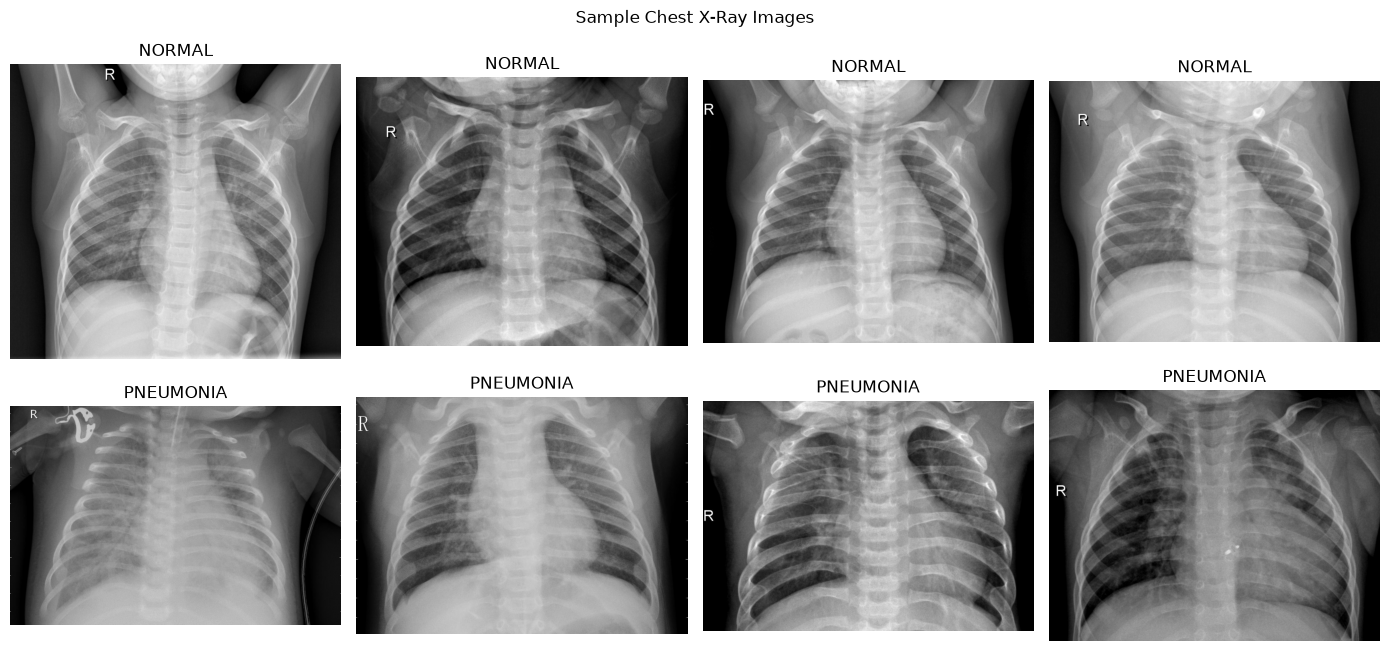

In [7]:
# Display sample images from each class

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, class_name in enumerate(classes):
    class_folder = dataset_path / "train" / class_name

    sample_files = [
        f for f in class_folder.iterdir()
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ][:4]

    for col, file in enumerate(sample_files):
        img = Image.open(file)

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle("Sample Chest X-Ray Images")
plt.tight_layout()
plt.show()

In [8]:
# Check all images for corruption

corrupted_files = []

for split in splits:
    for class_name in classes:
        folder = dataset_path / split / class_name

        for file in folder.iterdir():
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                try:
                    with Image.open(file) as img:
                        img.verify()
                except Exception:
                    corrupted_files.append(str(file))

print("Total images checked:", total_images)
print("Corrupted images:", len(corrupted_files))

if corrupted_files:
    print("\nCorrupted files:")
    for file in corrupted_files:
        print(file)
else:
    print("✅ No corrupted images found!")

Total images checked: 5856
Corrupted images: 0
✅ No corrupted images found!
